The governing equation for species $A$ in a plug flow reactor is 

$$
\frac{dF_A}{dV} = r_A = \sum_i a_i r_i
$$

where
$V$ is the volume of the reactor,
$F_{A}$ is the molar flow rate of $A$,
$r_A$ is the rate of generation of $A$,
$a_i$ is the stoichiometric coefficient of A in reaction $i$ ($a_i$ < 0 for reactants, $a_i$ > 0 for products),
and
$r_i$ is the rate of reaction $i$.

Consider a plug-flow reactor where the reactions

$$
A + B \rightarrow C \\
C + B \rightarrow D \\
D \rightarrow C + B
$$

occur. The rate laws of each reaction are

$$
r_1 = k_1 C_A C_B \\
r_2 = k_2 C_B C_C \\
r_3 = k_3 C_D
$$

where
$k_i$ is the rate constant of reaction $i$
and
$C_j$ is the concentration of species $j$.

The initial concentrations are 
$C_{Ao}$ = 150 mol/m$^3$, 
$C_{Bo}$ = 150 mol/m$^3$, 
and
$C_{Do}$ = 10 mol/m$^3$. 
The volumetric flow rate is $\dot V$ = 1000 m$^3$/hr.
The rate constants are 
$k_1$ = 1 m$^3$/(hr$\cdot$mol), 
$k_2$ = 0.6 m$^3$/(hr$\cdot$mol), 
and 
$k_3$ = 50 / hr. Plot the molar profiles as a function of reactor volume up to 100 m$^3$.

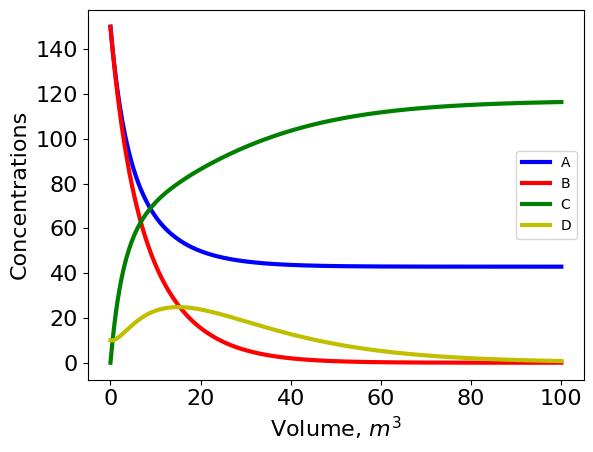

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as intx

def myfun(t,v):
    A,B,C,D = v   # unpacking the variables into two arrays 
    k1,k2,k3 = 1,0.6,50
    Vdot = 1000 # m^3/hr
    r1 = k1*A*B 
    r2 = k2*B*C
    r3 = k3*D

    dA = (-r1)/Vdot
    dB = (-r1-r2)/Vdot
    dC = (r1-r2+r3)/Vdot
    dD = (r2-r3)/Vdot
    return dA,dB,dC,dD  # unpack them in the order, ex, first equation should be for solving x 

# define volume range
vi,vf=0,100
v=np.linspace(vi,vf,1000)

# define initial conditions
c0 = (150,150,0,10) # comma at the end to make it a tuple

sol = intx.solve_ivp(myfun,(vi,vf),c0,t_eval=v)   # solve_ivp takes in function,range, and initial value 
#t = sol.t we are providing t, so dont need to unpack it
A,B,C,D = sol.y

plt.plot(v,A,'b-',lw=3,label='A')
plt.plot(v,B,'r-',lw=3,label='B')
plt.plot(v,C,'g-',lw=3,label='C')
plt.plot(v,D,'y-',lw=3,label='D')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel('Volume, $m^3$',fontsize=16)
plt.ylabel('Concentrations',fontsize=16)
plt.legend()